# Coursework Question 1: Maze solver (25 marks)

Code a maze solver using the maze provided in the brief as
“maze(1).png”. The resolution of the maze is 21 squares × 21 squares,
including the outer wall. Please read the whole exercise before starting.

The entrance is at the top. Each movement must be 1 square in any
orthogonal direction (up, down, left, right): diagonal movements are
not allowed.

## Coding

a) Save the maze into an appropriate variable/data structure and
display it in your terminal.

**Hint:** Matplotlib has some interesting functions to deal with images;
you are allowed to use them if needed.

b) Ask the user what approach they want to use (Backtracking or Las Vegas).

- **b.i)** When applying a Las Vegas approach, the end conditions are
  either you found the exit (successful) or you have completed 200 steps
  without finding the exit (unsuccessful).
- **b.ii)** For the Backtracking approach, you MUST explain in the report
  what is your rationale for choosing a particular direction and how
  you do the backtracking.

c) Give a visualization of all the visited “squares” (positions) when
the program ends, regardless of if it is successful or not.

## Testing

Please add in the report between 3 and 5 instances of testing your
programme. For each testing instance, you need to create a “bug report”
with the following information:

1. What went wrong or what were you trying to fix.
2. Screenshot of the error or issue.
3. How did you fix it and why it was important to fix.

After having a complete program, please compare Las Vegas and
Backtracking approaches and answer the following questions in your report:

a) What are their differences?

b) Which data structure/s would you use to implement this problem?
Give your reasoning.

c) What is the success rate of each of the algorithms after 10000 runs?

Record yourself going over your code explaining the rationale, and
highlighting the places of the code where you fixed it.

**Hint:** To know the success rate, record which runs give a successful
result. Then, divide the successful number of runs over the total
amount of runs.


Load and display it to check that it has been read correctly. Then to check its dimensions before converting it into a 21 × 21 grid.

Image shape: (210, 210, 4)


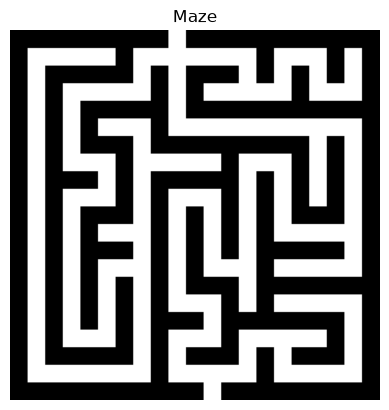

In [3]:
import matplotlib.pyplot as plt

maze_image = plt.imread("maze(1).png")
print("Image shape:", maze_image.shape)
plt.imshow(maze_image, cmap="gray")
plt.title("Maze")
plt.axis("off")
plt.show()

The maze contains 21 rows and 21 columns which means each square occupies 10 × 10 pixels. An empty list variable will store the completed rows.

In [8]:
maze_size = 21
square_size = 10
maze = []

The plan is to have two nested loops go through the 21 rows and columns. 

For each square, the centre pixel is read using the red colour channel. The image shape output already confirms 4 colour channels when the image was imported

Black squares are stored as walls (1), and white squares as passages (0). Each completed row is added to the maze list.

In [10]:
for row in range(maze_size):
    maze_row = []

    for column in range(maze_size):
        pixel_row = row * square_size + square_size // 2
        pixel_column = column * square_size + square_size // 2
        pixel = maze_image[pixel_row, pixel_column, 0]

        if pixel < 0.5:
            maze_row.append(1) 
        else:
            maze_row.append(0)

    maze.append(maze_row)

Need to check that the maze contains 21 rows and that every row contains 21 columns.

In [11]:
print("Number of rows:", len(maze))
correct_columns = all(len(row) == maze_size for row in maze)
print("Every row has 21 columns:", correct_columns)

Number of rows: 42
Every row has 21 columns: True


Print the maze row by row using its stored values: 1 represents a wall and 0 represents an open passage.

In [12]:
for row in maze:
    for square in row:
        print(square, end=" ")
    print()

1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 
1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 
1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 
1 0 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 
1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 1 
1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 1 
1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 1 
1 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 1 
1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 
1 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 1 
1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 1 1 0 1 
1 0 1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 
1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 
1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1 
1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 
1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1 
1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 1 1 0 1 
1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 
1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 
1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 
1 0 1 1 1 1

Running the conversion cell again added another 21 rows to the existing maze list, producing 42 rows instead of 21. 

Need to re-do the run

In [13]:
maze = []

for row in range(maze_size):
    maze_row = []

    for column in range(maze_size):
        pixel_row = row * square_size + square_size // 2
        pixel_column = column * square_size + square_size // 2

        pixel = maze_image[pixel_row, pixel_column, 0]

        if pixel < 0.5:
            maze_row.append(1)  # Wall
        else:
            maze_row.append(0)  # Passage

    maze.append(maze_row)

In [14]:
for row in maze:
    for square in row:
        print(square, end=" ")
    print()

1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1 
1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 
1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1 
1 0 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 
1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 
1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 1 
1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 1 
1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 1 
1 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 1 
1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 
1 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 1 
1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 1 1 0 1 
1 0 1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 
1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 
1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1 
1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 
1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1 
1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 1 1 0 1 
1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 
1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 


In [15]:
print("Number of rows:", len(maze))
print("Every row has 21 columns:",
      all(len(row) == maze_size for row in maze))

Number of rows: 21
Every row has 21 columns: True


The entrance is the open square in the top row, and the exit is the open square in the bottom row.

Positions are stored as (row, column) tuples . 

Python indexes start at 0, so the first row is 0 and the last row is 20.

In [16]:
entrance_column = maze[0].index(0)
exit_column = maze[-1].index(0)

entrance = (0, entrance_column)
exit_position = (len(maze) - 1, exit_column)

print("Entrance:", entrance)
print("Exit:", exit_position)

Entrance: (0, 9)
Exit: (20, 11)


The grid printed correctly using 1 for walls and 0 for passages, but I have noticed that it's very difficult to read. 

To improve readability, walls are displayed as ## and passages as two spaces. 

The stored grid still uses 1 and 0; only the display changes.

In [17]:
for row in maze:
    for square in row:
        if square == 1:
            print("##", end="")
        else:
            print("  ", end="")
    print()

##################  ######################
##          ##              ##      ##  ##
##  ##########  ##  ######  ##  ##  ##  ##
##  ##          ##  ##          ##      ##
##  ##  ##########  ######################
##  ##  ##      ##                      ##
##  ##  ######  ##################  ##  ##
##  ##      ##          ##      ##  ##  ##
##  ######  ##  ##########  ##  ##  ##  ##
##  ##      ##  ##      ##  ##  ##  ##  ##
##  ##  ######  ##  ##  ##  ##  ######  ##
##  ##  ##      ##  ##  ##  ##          ##
##  ##  ######  ##  ##  ##  ##########  ##
##  ##  ##      ##  ##      ##          ##
##  ##  ##  ##  ##  ######  ##############
##  ##  ##  ##  ##      ##  ##          ##
##  ##  ##  ##  ######  ##############  ##
##  ##      ##  ##      ##          ##  ##
##  ##########  ##  ######  ##  ######  ##
##              ##          ##          ##
######################  ##################


The entrance is (0, 9) and the exit is (20, 11).

Need to confirm that a position is valid if it is inside the grid and contains an open passage (0).

The boundary check happens before accessing the grid. 

This prevents out-of-range access and stops negative indexes from referring to the opposite side of the maze.

In [18]:
def is_valid_position(maze, row, column):
    if row < 0 or row >= len(maze):
        return False

    if column < 0 or column >= len(maze[0]):
        return False

    return maze[row][column] == 0

In [19]:
print("Entrance:", is_valid_position(maze, 0, 9))
print("Wall:", is_valid_position(maze, 0, 0))
print("Outside grid:", is_valid_position(maze, -1, 9))

Entrance: True
Wall: False
Outside grid: False


Gives the expected result where the entrance is valid, the wall is invalid, and the position outside the grid is invalid.

Each movement changes either the row or the column by one square. Diagonal movements aren't allowed.

For backtracking purposes, directions will be checked in the fixed order:

Down, Right, Up, Left. 

Down is checked first because the entrance is at the top and the exit is at the bottom. 

This is a simple search order, not a guarantee that moving down always leads towards the solution so will need to test this later. 

For now the directions will be looked at as : (change in row, change in column)

In [20]:
directions = [
    (1, 0),   # Down
    (0, 1),   # Right
    (-1, 0),  # Up
    (0, -1)   # Left
]

In [21]:
def solve_backtracking(maze, position, exit_position, visited, path):
    row, column = position

    if not is_valid_position(maze, row, column):
        return False
    if position in visited:
        return False

    visited.append(position)
    path.append(position)
    if position == exit_position:
        return True

    for row_change, column_change in directions:
        next_position = (row + row_change, column + column_change)

        if solve_backtracking(maze, next_position, exit_position,
                              visited, path):
            return True

    path.pop()
    return False

The function uses recursion to explore squares in the fixed order down, right, up, left. 

The aim is to make sure that the invalid and previously visited squares are skipped.

The visited list records all explored squares, including dead ends and the path list records the current route.

If all directions fail, path.pop() removes the current square from the route. The function returns False to the previous recursive call, which then tries another direction. I am using path.pop() because it removes a dead end from the current route. It stays in visited so we can display it later which will be very useful for testing.

The function returns True if it reaches the exit, or False if the search fails. It updates the visited and path lists passed into it after it has run

In [22]:
visited = []
path = []
success = solve_backtracking(
    maze, entrance, exit_position, visited, path
)
print("Exit found:", success)
print("Squares visited:", len(visited))

if success:
    print("Movements in final route:", len(path) - 1)
    print("Route starts at:", path[0])
    print("Route ends at:", path[-1])
else:
    print("No route to the exit was found.")

Exit found: True
Squares visited: 75
Movements in final route: 62
Route starts at: (0, 9)
Route ends at: (20, 11)


Created fresh visited and path lists for this attempt, then started the search at the entrance.

Needed to display whether the exit was found, how many squares were visited, and the number of movements in the final route. 

Currently shows that 75 squares were visited across 62 movements in hte final route however still need to check that every position in the route is an open passage and that consecutive positions are exactly one square apart horizontally or vertically. As mentioned before, diagonal travel is not allowed. 

In [25]:
valid_route = success

# Check that every square in the route is an open passage.
for row, column in path:
    if not is_valid_position(maze, row, column):
        valid_route = False

# Check each movement between consecutive squares.
for index in range(1, len(path)):
    previous_row, previous_column = path[index - 1]
    current_row, current_column = path[index]

    row_change = abs(current_row - previous_row)
    column_change = abs(current_column - previous_column)
    if row_change == 1 and column_change == 0:
        pass  # One square up or down
    elif row_change == 0 and column_change == 1:
        pass  # One square left or right
    else:
        valid_route = False

print("Route is valid:", valid_route)

Route is valid: True


That check passed. 

To be able to see this visually myself, the aim now is to have it display the maze with black walls and white passages, like the original maze image and mark every visited square in a colour, including explored dead ends.

The plot uses column numbers for the horizontal axis and row numbers for the vertical axis.

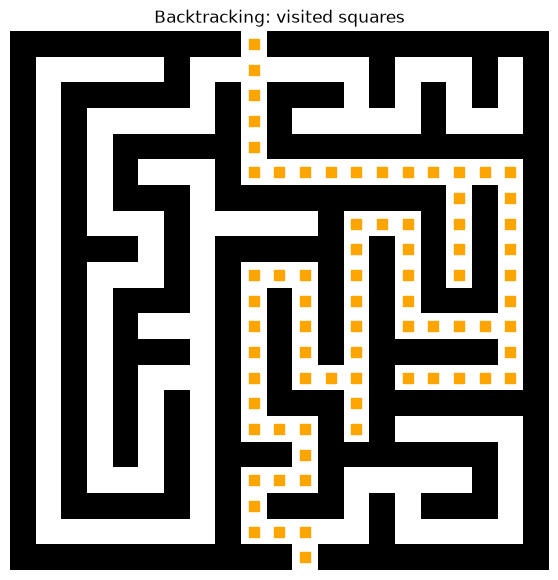

In [26]:
plt.figure(figsize=(7, 7))
plt.imshow(maze, cmap="gray_r", vmin=0, vmax=1)

for row, column in visited:
    plt.scatter(column, row, color="orange", marker="s", s=45)

plt.title("Backtracking: visited squares")
plt.axis("off")
plt.show()

It displays the maze with black walls and white passages and each loop marks each visited square in orange, including dead ends.

Column numbers give the horizontal positions, and row numbers give the vertical positions. This is still the convention we are using for the solver